# Parte Específica: Visualização Exploratória 3 — Heatmap Contatos × Inatividade

Dataset: BankChurners (`out/parte_especifica/bankchurners_tratado.csv`).

**Objetivo exploratório:** Investigar como a interação entre os dois principais indicadores positivos de atrito e desengajamento — quantidade de contatos com o banco (`Contacts_Count_12_mon`) e meses de inatividade (`Months_Inactive_12_mon`) nos últimos 12 meses — se relaciona com a taxa de cancelamento (`Attrition_Flag`), exibindo também o tamanho amostral (`n`) de cada célula para evitar leituras distorcidas em combinações raras.

In [1]:
# [IA] Claude Code – visualizacao exploratoria 3 (heatmap contatos x inatividade): importacao das bibliotecas e leitura dos dados
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="white", context="notebook")

PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

CAMINHO_TRATADO = PASTA_SAIDA / "bankchurners_tratado.csv"
CAMINHO_BRUTO = Path("../../data/parte_especifica/BankChurners.csv")
CAMINHO_DADOS = CAMINHO_TRATADO if CAMINHO_TRATADO.exists() else CAMINHO_BRUTO

df = pd.read_csv(CAMINHO_DADOS)
if pd.api.types.is_numeric_dtype(df["Attrition_Flag"]):
    df["cancelou"] = df["Attrition_Flag"].astype(int)
else:
    df["cancelou"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)

taxa_geral = df["cancelou"].mean() * 100
print(f"Arquivo: {CAMINHO_DADOS.name} | Total de clientes: {len(df)} | Taxa geral de cancelamento: {taxa_geral:.2f}%")

Arquivo: bankchurners_tratado.csv | Total de clientes: 10127 | Taxa geral de cancelamento: 16.07%


In [2]:
# [IA] Claude Code – visualizacao exploratoria 3 (heatmap contatos x inatividade): tabela agregada
taxa_piv = (
    df.pivot_table(
        index="Contacts_Count_12_mon",
        columns="Months_Inactive_12_mon",
        values="cancelou",
        aggfunc="mean",
    )
    * 100
)

contagem_piv = df.pivot_table(
    index="Contacts_Count_12_mon",
    columns="Months_Inactive_12_mon",
    values="cancelou",
    aggfunc="count",
    fill_value=0,
)

print("Taxa de cancelamento (%) por Contatos x Meses Inativos:")
display(taxa_piv.round(1))
print("\nQuantidade de clientes (n) em cada combinacao:")
display(contagem_piv)

Taxa de cancelamento (%) por Contatos x Meses Inativos:


Months_Inactive_12_mon,0,1,2,3,4,5,6
Contacts_Count_12_mon,,,,,,,
0,0.0,0.0,0.8,3.9,0.0,0.0,0.0
1,0.0,1.6,6.5,11.2,10.6,10.0,4.0
2,40.0,3.6,12.3,17.1,19.4,8.9,17.2
3,63.6,6.2,19.5,25.5,41.6,21.3,20.5
4,100.0,6.0,21.7,29.7,40.4,33.3,5.9
5,NaN,16.7,22.0,42.5,62.5,100.0,66.7
6,100.0,100.0,100.0,100.0,100.0,100.0,100.0



Quantidade de clientes (n) em cada combinacao:


Months_Inactive_12_mon,0,1,2,3,4,5,6
Contacts_Count_12_mon,,,,,,,
0,2,100,121,154,11,6,5
1,5,364,475,534,66,30,25
2,5,723,1064,1221,129,56,29
3,11,730,1085,1288,161,61,44
4,5,285,461,546,57,21,17
5,0,30,59,73,8,3,3
6,1,1,17,30,3,1,1


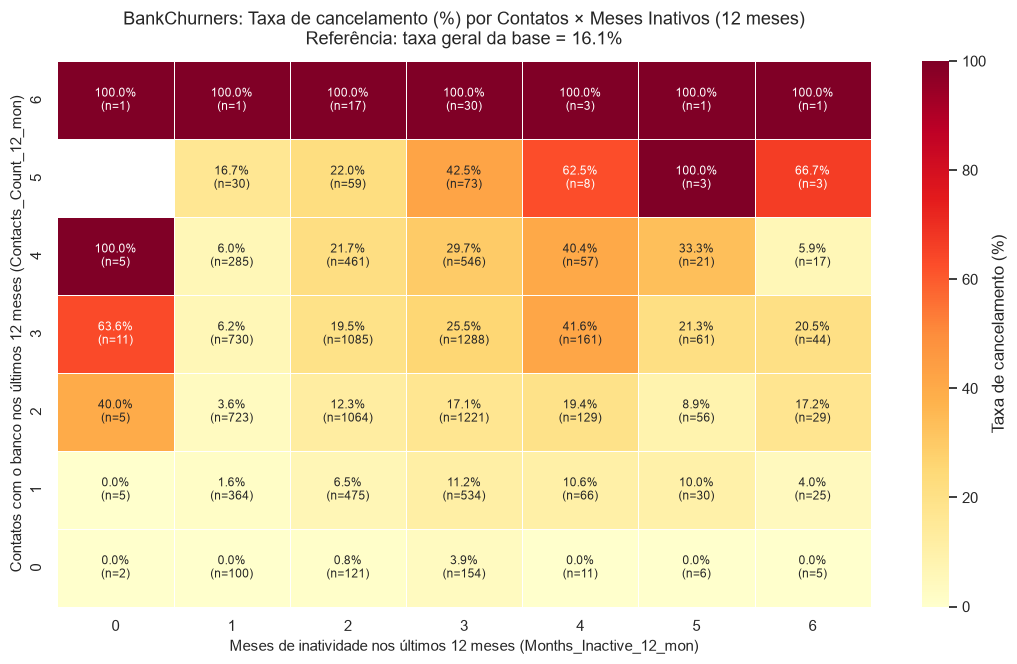

Salvo em: ..\..\out\parte_especifica\viz_exploratoria_3_heatmap_contatos_inatividade.png


In [3]:
# [IA] Claude Code – visualizacao exploratoria 3 (heatmap contatos x inatividade): grafico
anotacoes = pd.DataFrame(index=taxa_piv.index, columns=taxa_piv.columns, dtype=str)
for i in taxa_piv.index:
    for j in taxa_piv.columns:
        n_obs = int(contagem_piv.loc[i, j])
        val = taxa_piv.loc[i, j]
        if n_obs == 0 or pd.isna(val):
            anotacoes.loc[i, j] = "-"
        else:
            anotacoes.loc[i, j] = f"{val:.1f}%\n(n={n_obs})"

fig, ax = plt.subplots(figsize=(11, 6.8))
sns.heatmap(
    taxa_piv,
    annot=anotacoes,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Taxa de cancelamento (%)"},
    annot_kws={"fontsize": 8.5},
    ax=ax,
)

ax.set_title(
    f"BankChurners: Taxa de cancelamento (%) por Contatos × Meses Inativos (12 meses)\n"
    f"Referência: taxa geral da base = {taxa_geral:.1f}%",
    fontsize=13,
    pad=12,
)
ax.set_xlabel("Meses de inatividade nos últimos 12 meses (Months_Inactive_12_mon)", fontsize=11)
ax.set_ylabel("Contatos com o banco nos últimos 12 meses (Contacts_Count_12_mon)", fontsize=11)
ax.invert_yaxis()

fig.tight_layout()
caminho_fig = PASTA_SAIDA / "viz_exploratoria_3_heatmap_contatos_inatividade.png"
fig.savefig(caminho_fig, dpi=150, bbox_inches="tight")
plt.show()
print("Salvo em:", caminho_fig)

## Leitura exploratória

- **Escolha do gráfico:** Um **mapa de calor (heatmap)** é ideal para cruzar duas variáveis discretas de contagem (`0` a `6`) com uma métrica contínua agregada (taxa de cancelamento em %), revelando zonas de risco sem sobreposição de pontos.
- **Efeito combinado de atrito e inatividade:** Clientes com **0 ou 1 contato** e baixa inatividade mantêm taxas de cancelamento muito abaixo da média geral (16,1%). À medida que os contatos sobem para **3, 4 ou 5** em conjunto com **3 ou 4 meses inativos**, a taxa salta para a faixa de **25% a 62,5%**.
- **Faixa crítica de 6 contatos:** Independentemente da quantidade de meses inativos, **100% dos clientes com 6 contatos** nos últimos 12 meses cancelaram a conta (sinal extremo de atrito/insatisfação).
- **Cautela com amostras pequenas (`n`):** Incluir `(n=...)` em cada célula mostra que alguns valores altos na coluna `0 meses inativos` (como `40,0%`, `63,6%` e `100,0%`) vêm de grupos muito pequenos (`n <= 11`), enquanto o grande volume de clientes se concentra entre `1` e `3` meses inativos e `1` a `4` contatos.